# Notebook 04 — Train T5 to Pick Tools

The same idea as the intent classifier, one level more precise. T5 reads a message and **writes** the tools to call:

```
input : "tools: Why is my October bill so high?"
output: "search_help_articles, get_bill"
```

Everything runs on a **CPU**. The code is the same training loop as the intent notebooks, written out step by step.

| Section | What it does |
|---|---|
| 1 | Setup and settings |
| 2 | Load the data |
| 3 | Load FLAN-T5-small and try it before training |
| 4 | Turn T5's output into a clean tool list |
| 5 | Train, checking validation after every pass |
| 6 | The training curve |
| 7 | First score on the gold test set |
| 8 | Per-tool scores |
| 9 | The mistakes |
| 10 | Save |

## 1 · Setup and settings

In [ ]:
# Run once if needed:
# %pip install -q torch transformers sentencepiece pandas scikit-learn matplotlib

import copy
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.metrics import classification_report
from sklearn.preprocessing import MultiLabelBinarizer
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

MODEL_NAME    = "google/flan-t5-small"   # ~77M parameters
PREFIX        = "tools: "                # every input starts with this task prefix
MAX_EPOCHS    = 12                       # at most 12 passes over the training data
PATIENCE      = 2                        # stop after 2 passes without a better validation score
BATCH_SIZE    = 16
LEARNING_RATE = 5e-4
SEED          = 42

random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count())
pd.set_option("display.max_colwidth", 90)

TOPIC_DIR = Path.cwd().parents[2]
TOOLS_DIR = TOPIC_DIR / "data" / "tools"
MODEL_DIR = Path.cwd().parents[1] / "models" / "flan-t5-small-tools"

print(f"PyTorch {torch.__version__} · {os.cpu_count()} CPU threads")

PyTorch 2.14.1+cpu · 4 CPU threads


## 2 · Load the data

In [2]:
catalogue = json.load(open(TOOLS_DIR / "tools.json", encoding="utf-8"))     # Notebook 01
TOOL_ORDER = catalogue["tool_order"]

train         = pd.read_csv(TOOLS_DIR / "tool_train.csv", keep_default_na=False)           # Notebook 03
val           = pd.read_csv(TOOLS_DIR / "tool_val.csv", keep_default_na=False)
val_realistic = pd.read_csv(TOOLS_DIR / "tool_val_realistic.csv", keep_default_na=False)
gold          = pd.read_csv(TOOLS_DIR / "gold_tool_test.csv", keep_default_na=False)       # Notebook 02

# the best pass is chosen on both validation sets together
select = pd.concat([val, val_realistic], ignore_index=True)

print(f"train {len(train)} · val {len(val)} · realistic val {len(val_realistic)} · gold test {len(gold)}")

train 1379 · val 325 · realistic val 40 · gold test 103


## 3 · Load FLAN-T5-small and try it before training

FLAN-T5 has never seen our tool names. Before training it can only guess.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

def generate(queries, batch_size=32):
    model.eval()
    outputs = []
    
    for start in range(0, len(queries), batch_size):
        batch = []
        
        for query in queries[start:start + batch_size]:
            batch.append(PREFIX + query)
            
        inputs = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=96)
        
        with torch.no_grad():
            ids = model.generate(**inputs, max_new_tokens=48, num_beams=1)
            
        outputs.extend(tokenizer.batch_decode(ids, skip_special_tokens=True))
        
    return outputs

examples = ["Why is my October bill so high?", 
            "Block my SIM, my phone was stolen.", 
            "Thanks, bye!"]

for query, output in zip(examples, generate(examples)):
    print(f"{query:40} → {output!r}")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Why is my October bill so high?          → 'a bill that is not refundable'
Block my SIM, my phone was stolen.       → 'Tools: Block my SIM, my phone was stolen.'
Thanks, bye!                             → 'Tools: Thanks!'


Not useful yet. It has to learn our 18 tool names and when to use each.

## 4 · Turn T5's output into a clean tool list

T5 writes free text, so it can write a tool name that doesn't exist, repeat one, or put them in any order. `clean_tools` keeps only real tool names, in the fixed catalogue order:

| T5 writes | `clean_tools` returns |
|---|---|
| `get_bill, search_help_articles` | `search_help_articles, get_bill` |
| `get_bil, search_help_articles` | `search_help_articles` (the typo is dropped) |
| `none` | `none` |
| `banana` | `` (empty: nothing valid) |

In [4]:
def clean_tools(text):
    parts = []
    for part in text.split(","):
        parts.append(part.strip().lower())

    ordered = []
    for name in TOOL_ORDER:
        if name in parts:
            ordered.append(name)

    if len(ordered) > 0:
        return ", ".join(ordered)
    if "none" in parts:
        return "none"
    return ""

def exact_match(df):
    predicted = []
    for output in generate(list(df["query"])):
        predicted.append(clean_tools(output))
    correct = 0
    for p, t in zip(predicted, df["tools"]):
        if p == t:
            correct += 1
    return correct / len(df)

for text in ["get_bill, search_help_articles", "get_bil, search_help_articles", "none", "banana"]:
    print(f"{text:35} → {clean_tools(text)!r}")

get_bill, search_help_articles      → 'search_help_articles, get_bill'
get_bil, search_help_articles       → 'search_help_articles'
none                                → 'none'
banana                              → ''


## 5 · Train, checking validation after every pass

Each pass (**epoch**) goes once through all training pairs in small batches. After each pass we score both validation sets and **keep a copy of the best model so far**. If it hasn't improved for `PATIENCE` passes, we stop.

On a typical laptop CPU, one pass takes a few minutes.

In [5]:
pairs = []
for query, tools in zip(train["query"], train["tools"]):
    pairs.append((PREFIX + query, tools))

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

history = []
best_score = -1.0
best_state = None
passes_without_improvement = 0
start = time.perf_counter()

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    random.shuffle(pairs)
    total_loss = 0.0
    batches = 0

    for i in range(0, len(pairs), BATCH_SIZE):
        batch = pairs[i:i + BATCH_SIZE]
        inputs = []
        targets = []
        for x, y in batch:
            inputs.append(x)
            targets.append(y)

        encoded = tokenizer(inputs, return_tensors="pt", padding=True, truncation=True, max_length=96)
        labels = tokenizer(targets, return_tensors="pt", padding=True, truncation=True, max_length=48).input_ids
        labels[labels == tokenizer.pad_token_id] = -100        # don't learn from padding

        loss = model(**encoded, labels=labels).loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        total_loss += loss.item()
        batches += 1

    select_score    = exact_match(select)
    realistic_score = exact_match(val_realistic)
    minutes = (time.perf_counter() - start) / 60
    history.append({"epoch": epoch, "train loss": total_loss / batches,
                    "validation": select_score, "realistic val": realistic_score})
    print(f"epoch {epoch:2} · loss {total_loss / batches:.3f} · validation {select_score:.0%} · "
          f"realistic {realistic_score:.0%} · {minutes:.1f} min")

    if select_score > best_score:
        best_score = select_score
        best_state = copy.deepcopy(model.state_dict())
        passes_without_improvement = 0
    else:
        passes_without_improvement += 1
        if passes_without_improvement >= PATIENCE:
            print(f"No improvement for {PATIENCE} passes: stopping.")
            break

model.load_state_dict(best_state)
history = pd.DataFrame(history)
best_epoch = int(history.loc[history["validation"].idxmax(), "epoch"])
print(f"Kept epoch {best_epoch} · validation {best_score:.0%}")

epoch  1 · loss 0.743 · validation 65% · realistic 45% · 12.8 min
epoch  2 · loss 0.061 · validation 77% · realistic 72% · 23.1 min
epoch  3 · loss 0.021 · validation 84% · realistic 70% · 29.1 min
epoch  4 · loss 0.007 · validation 81% · realistic 62% · 36.5 min
epoch  5 · loss 0.007 · validation 79% · realistic 65% · 43.6 min
No improvement for 2 passes: stopping.
Kept epoch 3 · validation 84%


## 6 · The training curve

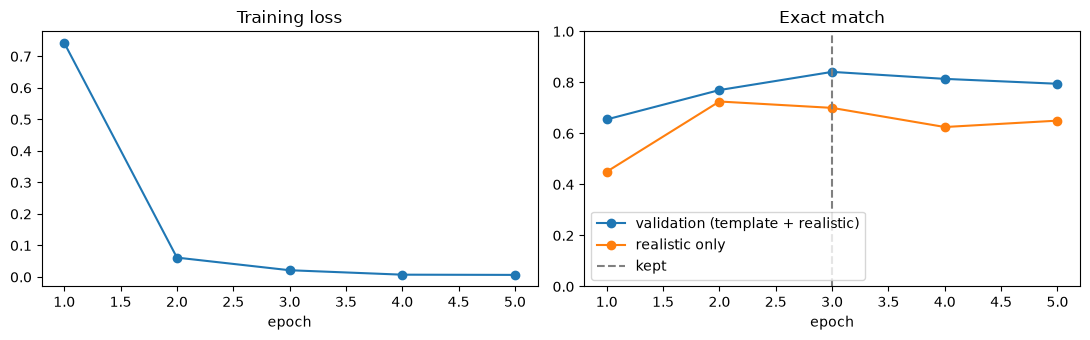

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.5))

left.plot(history["epoch"], history["train loss"], marker="o")
left.set_title("Training loss")
left.set_xlabel("epoch")

right.plot(history["epoch"], history["validation"], marker="o", label="validation (template + realistic)")
right.plot(history["epoch"], history["realistic val"], marker="o", label="realistic only")
right.axvline(best_epoch, color="grey", linestyle="--", label="kept")
right.set_title("Exact match")
right.set_xlabel("epoch")
right.set_ylim(0, 1)
right.legend()

plt.tight_layout()
plt.show()

**How to read it:** loss should fall steadily. The validation lines should rise and then level off. A big gap between the two validation lines (template-made vs hand-written) means T5 is learning the **style** of our templates more than the task: the problem from intent Notebook 04.

## 7 · First score on the gold test set

Scored with the rule from Notebook 02: correct if the predicted tools equal the gold `tools` **or** any `accepted` alternative.

In [7]:
def is_correct(predicted, tools, accepted):
    if predicted == tools:
        return True
    if accepted != "":
        for option in accepted.split(" | "):
            if predicted == option:
                return True
    return False


start = time.perf_counter()
outputs = generate(list(gold["query"]))
ms_per_query = (time.perf_counter() - start) / len(gold) * 1000

predicted = []
for output in outputs:
    predicted.append(clean_tools(output))
gold["t5"] = predicted

correct = []
for i, row in gold.iterrows():
    correct.append(is_correct(row["t5"], row["tools"], row["accepted"]))
gold["t5_correct"] = correct

originals = gold[gold["original"]]
new       = gold[gold["source"] == "new"]

print(f"T5 on all {len(gold)} gold queries:  {gold['t5_correct'].mean():.0%}")
print(f"  {len(originals)} originals (real customer messages): {originals['t5_correct'].mean():.0%}")
print(f"  {len(new)} new tool-focused queries:          {new['t5_correct'].mean():.0%}")
print(f"Speed: {ms_per_query:.0f} ms per query on this CPU")

T5 on all 103 gold queries:  73%
  31 originals (real customer messages): 68%
  22 new tool-focused queries:          95%
Speed: 59 ms per query on this CPU


In [8]:
def tool_count(tools):
    if tools == "none":
        return "no tool"
    if len(tools.split(", ")) == 1:
        return "1 tool"
    return "2-3 tools"


gold["size"] = gold["tools"].apply(tool_count)
gold.groupby("size")["t5_correct"].agg(["count", "mean"]).rename(columns={"count": "queries", "mean": "correct"}).round(2)

,queries,correct
size,,
1 tool,65,0.66
2-3 tools,17,0.82
no tool,21,0.86


Multi-tool queries are the hardest: every tool must be right, with nothing extra.

## 8 · Per-tool scores

For each tool: **precision** = when T5 calls it, how often it should have; **recall** = of the queries that need it, how many got it. (Measured against the main gold `tools`, without alternatives.)

In [9]:
def tool_lists(column):
    lists = []
    for text in column:
        if text == "":
            lists.append([])
        else:
            lists.append(text.split(", "))
    return lists


ALL_LABELS = TOOL_ORDER + ["none"]
mlb = MultiLabelBinarizer(classes=ALL_LABELS)
y_true = mlb.fit_transform(tool_lists(gold["tools"]))
y_pred = mlb.transform(tool_lists(gold["t5"]))

report = classification_report(y_true, y_pred, target_names=ALL_LABELS, output_dict=True, zero_division=0)
per_tool = pd.DataFrame(report).T.loc[ALL_LABELS, ["precision", "recall", "support"]]
per_tool["support"] = per_tool["support"].astype(int)
per_tool.round(2)

,precision,recall,support
search_help_articles,0.69,0.74,27
get_balance,0.75,1.00,3
get_active_packs,0.33,1.00,3
get_bill,1.00,1.00,3
get_usage,0.22,1.00,2
get_recharge_history,0.50,0.67,3
get_kyc_status,0.67,1.00,2
get_port_status,0.50,0.50,2
get_barring_reason,1.00,1.00,2
check_network_outage,0.80,1.00,4


`support` is how many gold queries need the tool. Tools with a support of 1–3 can swing from 0 to 1 on a single query, so read those rows with care.

## 9 · The mistakes

In [10]:
wrong = gold[~gold["t5_correct"]]
print(len(wrong), "wrong of", len(gold))
wrong[["query", "tools", "accepted", "t5", "note"]]

28 wrong of 103


,query,tools,accepted,t5,note
2,Activate Wi-Fi calling for me.,search_help_articles,,activate_pack,"Catalogue gap: Wi-Fi calling is switched on in the phone's settings, so the right move..."
5,Block roaming on my number until further notice.,deactivate_service,,,
10,Why did my Smart 299 run out so quickly?,ask_clarifying_question,get_active_packs | none,"search_help_articles, get_active_packs",Data or validity? Looking up the packs also answers both.
11,Why is it behaving weirdly?,ask_clarifying_question,none,"search_help_articles, get_usage",
13,It's gone again.,ask_clarifying_question,none,get_active_packs,
18,It isn't showing up.,ask_clarifying_question,none,search_help_articles,
20,If my number isn't working by tonight I'm coming to your store to smash the counter.,transfer_to_agent,,"search_help_articles, get_active_packs",Replaces Lesson 08's placeholder text.
21,Is there a person I can speak with?,transfer_to_agent,,get_usage,
22,Raise this with someone senior on your side.,transfer_to_agent,"raise_complaint, transfer_to_agent",raise_complaint,
28,What is the validity of the Smart 599 prepaid plan?,search_help_articles,search_plan_catalogue,get_balance,"One named plan: article first, but the catalogue also has the answer."


**Questions to ask of each mistake:**
- Is it a **confusable pair** from Notebook 01 (`get_bill` vs `get_usage`, `get_balance` vs `get_active_packs`)?
- Is it a **"how do I…" near miss** called as a lookup or an action?
- Did T5 get **part** of a multi-tool answer (one tool missing, or one extra)?
- Is it a **catalogue gap** query (Wi-Fi calling, physical SIM, deposit refund)?

The patterns tell us what to fix: templates, descriptions, or the data balance.

## 10 · Save

In [11]:
model.save_pretrained(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

gold[["query", "tools", "accepted", "original", "source", "t5", "t5_correct"]].to_csv(
    TOOLS_DIR / "t5_tool_test_predictions.csv", index=False)
history.to_csv(TOOLS_DIR / "t5_tool_training_history.csv", index=False)

print("Model saved to", MODEL_DIR)
print("Predictions saved to t5_tool_test_predictions.csv")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to d:\gridflowAI\00-ALL-COURSES-REPO\Corporate-Trainings\01-genai-developers\19-Agentic-RAG_optimizations\lesson_part_08_Intent_classification\models\flan-t5-small-tools
Predictions saved to t5_tool_test_predictions.csv


## What's next

**Notebook 05 · LLM tool calls:** give `gpt-5.6-luna` the 18 tool definitions and the same 103 gold queries, and record which tools it calls. Then Notebook 06 compares the two and tests T5 as a checker on the LLM's choices.